# Лабораторна робота 5. Власне донавчання моделі (`ft_project.ipynb`)

## 1.1. Задача: Автоматичний фармаконагляд і тріаж побічних реакцій на лікарські засоби (Adverse Drug Events Triage)

### Опис прикладної задачі та сценарій використання
- **Хто користувач:** Медичні інформаційні системи (МІС), клінічні фармацевти, відділи фармаконагляду (Pharmacovigilance) фармацевтичних компаній та телемедичні платформи.
- **Що подається на вхід:** Коротке текстове повідомлення з медичної картки пацієнта, звіту лікаря або звернення в чат-бот клініки англійською мовою, де згадується прийом певного медикаменту та стан пацієнта.
- **Що має бути на виході:** Валідний JSON-об'єкт строго заданої схеми без жодного зайвого тексту чи Markdown-обгорток:
  `{"ade_status": "<ADVERSE_EVENT | NO_EVENT>", "clinical_action": "<URGENT_PHARMACOVIGILANCE | ROUTINE_LOG>"}`
  - Якщо в тексті описано побічну реакцію, токсичність або ускладнення, викликане препаратом — `ade_status = "ADVERSE_EVENT"`, а система автоматично скеровує кейс на негайний розгляд фармаконагляду (`clinical_action = "URGENT_PHARMACOVIGILANCE"`).
  - Якщо в тексті згадується звичайне лікування, дозування або хвороба без побічної дії препарату — `ade_status = "NO_EVENT"`, і запис просто архівується в історії хвороби (`clinical_action = "ROUTINE_LOG"`).

### Чому для цієї задачі потрібне саме донавчання (SFT), а не промпт чи RAG?
1. **Чому не підходить RAG:** Задача полягає не в пошуку зовнішніх фактів у базі знань, а в глибокому семантичному розрізненні причинно-наслідкового зв'язку в конкретному реченні: чи симптом є *причиною призначення* препарату (показанням до застосування), чи *наслідком прийому* препарату (побічною реакцією).
2. **Недоліки детального промпту (Zero-shot / Few-shot):**
   - У медичних текстах завжди присутні назви хвороб, симптомів і ліків. Недонавчена мала LLM реагує на «тривожні» медичні слова (наприклад, *pain, seizure, tumor, coma*) і помилково класифікує звичайні показання до лікування як побічну дію препарату (високий рівень *False Positives*).
   - Передача детальних клінічних інструкцій і few-shot прикладів у кожному запиті збільшує довжину промпту з ~12 до ~220 токенів, що підвищує вартість та затримку обробки мільйонів медичних записів у ~15 разів.
   - Донавчання (SFT з LoRA) дозволяє закріпити специфіку клінічної розмітки та строгий JSON-формат безпосередньо у вагах компактної моделі `Qwen3-0.6B`.

In [1]:
!pip install -q "transformers>=4.55.0" "trl>=1.17" "peft" "bitsandbytes" "datasets" "accelerate" "scikit-learn" "matplotlib"
!pip uninstall -q -y torchao

import gc
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from peft import LoraConfig, PeftModel
from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

set_seed(42)
assert torch.cuda.is_available(), "Увімкніть GPU: Runtime -> Change runtime type -> T4 GPU"
print(f"GPU: {torch.cuda.get_device_name()}")
print(f"Памʼять GPU: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

GPU: Tesla T4
Памʼять GPU: 15.6 GB


## 1.2. Модель і дані

### Вибір моделі: `Qwen/Qwen3-0.6B` (Instruct)
- **Чому Instruct, а не Base:** Модель уже знайома з форматом діалогу ChatML (`<|im_start|>...<|im_end|>`), розуміє системні інструкції та базовий синтаксис JSON, що дозволяє досягти високої якості вже за 120 кроків SFT.
- **Чому розмір 0.6B:** Для високочастотного потокового тріажу медичних записів критично важлива низька затримка (latency) і можливість локального розгортання в клініці (on-premise, через вимоги конфіденційності медичних даних HIPAA/GDPR) на недорогих GPU. Модель займає лише 1.2 ГБ у `fp16` і ідеально вміщується в безкоштовний Google Colab T4.

### Опис датасету: `SetFit/ade_corpus_v2_classification` (Adverse Drug Reaction Corpus v2)
- **Джерело:** Hugging Face Hub (`SetFit/ade_corpus_v2_classification`), побудований на основі рецензованих біомедичних звітів MEDLINE/PubMed (Gurulingappa et al., *Journal of Biomedical Informatics*).
- **Ліцензія:** MIT / CC-BY-4.0 (відкритий академічний датасет).
- **Кількість прикладів і формат:** Понад 23 000 речень із медичних звітів із колонками `text` (речення) та `label` (`1` — присутня побічна реакція на препарат, `0` — побічної реакції немає).
- **Перетворення та поділ:** Після дедуплікації перетворюємо дані у діалоговий формат `messages` із цільовим JSON `{"ade_status": ..., "clinical_action": ...}` та розділяємо без перетинів на:
  - **Тренувальний набір (`train_dataset`):** 2400 прикладів;
  - **Валідаційний набір (`val_dataset`):** 200 прикладів;
  - **Тестовий набір (`test_dataset`):** 500 прикладів (використовується виключно для фінальної оцінки до і після донавчання).

In [2]:
raw_ds = load_dataset("SetFit/ade_corpus_v2_classification", split="train")
print("Оригінальний датасет:", raw_ds)

# Дедуплікація за текстом речення (без урахування регістру та пробілів)
seen, keep_indices = set(), []
for idx, text in enumerate(raw_ds["text"]):
    norm_text = text.strip().lower()
    if norm_text not in seen:
        seen.add(norm_text)
        keep_indices.append(idx)

dedup_ds = raw_ds.select(keep_indices).shuffle(seed=42)
print(f"Кількість прикладів до дедуплікації: {len(raw_ds)}, після дедуплікації: {len(dedup_ds)}")

print("\nПриклади з датасету:")
for ex in dedup_ds.select(range(5)):
    status = "ADVERSE_EVENT (1)" if ex["label"] == 1 else "NO_EVENT (0)"
    print(f"[{status:<17}] {ex['text']}")

SHORT_PROMPT = "Analyze the clinical note for adverse drug events. Reply with JSON only."

LONG_PROMPT = """You are a clinical pharmacovigilance AI assistant.
Analyze the medical sentence and determine if it describes an Adverse Drug Event (ADE) — a harmful, unintended side effect caused by a medication.
Note: If a disease or symptom is the reason the drug was prescribed (indication) or unrelated to the drug, it is NOT an adverse event.

Reply with a single valid JSON object and nothing else, using this exact schema:
{"ade_status": "<ADVERSE_EVENT or NO_EVENT>", "clinical_action": "<URGENT_PHARMACOVIGILANCE or ROUTINE_LOG>"}

Rules:
- Use "ade_status": "ADVERSE_EVENT" and "clinical_action": "URGENT_PHARMACOVIGILANCE" ONLY when the text explicitly states an adverse reaction/toxicity caused by a drug.
- Use "ade_status": "NO_EVENT" and "clinical_action": "ROUTINE_LOG" when there is no adverse drug reaction."""

def to_messages(example):
    is_ade = int(example["label"]) == 1
    target_json = json.dumps({
        "ade_status": "ADVERSE_EVENT" if is_ade else "NO_EVENT",
        "clinical_action": "URGENT_PHARMACOVIGILANCE" if is_ade else "ROUTINE_LOG",
    })
    return {
        "messages": [
            {"role": "system", "content": SHORT_PROMPT},
            {"role": "user", "content": example["text"]},
            {"role": "assistant", "content": target_json},
        ],
        "label_int": int(example["label"]),
        "chat_template_kwargs": {"enable_thinking": False},
    }

# Формуємо непересічні вибірки: 2400 train, 200 val, 500 test
train_val_ds = dedup_ds.select(range(2600)).map(to_messages, remove_columns=dedup_ds.column_names)
splits = train_val_ds.train_test_split(test_size=200, seed=42)
train_dataset, val_dataset = splits["train"], splits["test"]
test_dataset = dedup_ds.select(range(2600, 3100)).map(to_messages, remove_columns=dedup_ds.column_names)

print(f"\nРозміри вибірок -> Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")
print("Приклад у форматі messages:\n", train_dataset[0]["messages"])

README.md:   0%|          | 0.00/331 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train.jsonl:   0%|          | 0.00/3.20M [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/1.05M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/17637 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5879 [00:00<?, ? examples/s]

Оригінальний датасет: Dataset({
    features: ['text', 'label', 'label_text'],
    num_rows: 17637
})
Кількість прикладів до дедуплікації: 17637, після дедуплікації: 15918

Приклади з датасету:
[NO_EVENT (0)     ] In recent years there has been an increase in the use of ACE inhibitors in the paediatric population.
[ADVERSE_EVENT (1)] CONCLUSION: A woman receiving enoxaparin every 12 hours developed signs and symptoms of hepatotoxicity after the second dose.
[NO_EVENT (0)     ] Alternatively, certain viral infections could induce leukopenia.
[ADVERSE_EVENT (1)] Recurrent hypotension immediately after seizures in nortriptyline overdose.
[NO_EVENT (0)     ] RESULTS: The study patients were observed up to 4 years, and none of them reported any problems.


Map:   0%|          | 0/2600 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]


Розміри вибірок -> Train: 2400, Val: 200, Test: 500
Приклад у форматі messages:
 [{'content': 'Analyze the clinical note for adverse drug events. Reply with JSON only.', 'role': 'system'}, {'content': 'She also took nifedipine, atenolol, clonidine, prednisone, aspirin, and potassium chloride throughout pregnancy.', 'role': 'user'}, {'content': '{"ade_status": "NO_EVENT", "clinical_action": "ROUTINE_LOG"}', 'role': 'assistant'}]


## 1.3. Модель до донавчання та вибір метрик

### Обґрунтування метрик
Оскільки наша модель генерує структуровану JSON-відповідь для медичного тріажу, а класи в датасеті незбалансовані (близько 30% прикладів є побічними реакціями `ADVERSE_EVENT`, а 70% — `NO_EVENT`), ми використовуємо чотири показники:
1. **Частка чистих/валідних JSON (`Valid JSON, %`):** перевіряє, чи здатна автоматизована система розпарсити відповідь моделі через `json.loads()` і чи присутні обидва обов'язкові ключі `ade_status` та `clinical_action` зі списку дозволених значень.
2. **Точність статусу (`Accuracy ade_status, %`):** загальна частка правильних класифікацій на тестовому наборі з 500 прикладів.
3. **Точність дії (`Accuracy clinical_action, %`):** перевіряє узгодженість другого поля JSON (чи правильно модель призначила маршрут тікета відповідно до статусу).
4. **F1-score для класу `ADVERSE_EVENT` (`F1 (ADE), %`):** **головна метрика задачі**. Через дисбаланс класів звичайна `Accuracy` може бути високою навіть тоді, коли модель пропускає небезпечні побічні реакції або навпаки — б'є хибну тривогу на кожному реченні. `F1` балансує *Precision* (відсутність хибних тривог) і *Recall* (повноту виявлення реальних ускладнень).

In [3]:
MODEL_NAME = "Qwen/Qwen3-0.6B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print(f"Довжина SHORT_PROMPT: {len(tokenizer(SHORT_PROMPT)['input_ids'])} токенів")
print(f"Довжина LONG_PROMPT:  {len(tokenizer(LONG_PROMPT)['input_ids'])} токенів")

ALLOWED_STATUS = {"ADVERSE_EVENT", "NO_EVENT"}
ALLOWED_ACTION = {"URGENT_PHARMACOVIGILANCE", "ROUTINE_LOG"}

def generate_batch(model, texts, system_prompt, max_new_tokens=50):
    prompts = [
        tokenizer.apply_chat_template(
            [{"role": "system", "content": system_prompt}, {"role": "user", "content": t}],
            tokenize=False, add_generation_prompt=True, enable_thinking=False,
        )
        for t in texts
    ]
    tokenizer.padding_side = "left"
    inputs = tokenizer(prompts, return_tensors="pt", padding=True).to(model.device)
    tokenizer.padding_side = "right"
    with torch.no_grad():
        outputs = model.generate(
            **inputs, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tokenizer.pad_token_id
        )
    new_tokens = outputs[:, inputs["input_ids"].shape[1]:]
    return [ans.strip() for ans in tokenizer.batch_decode(new_tokens, skip_special_tokens=True)]

def parse_response(ans):
    clean_flag = False
    try:
        json.loads(ans)
        clean_flag = True
    except json.JSONDecodeError:
        pass

    text = ans.strip()
    if text.startswith("```"):
        text = text.strip("`").removeprefix("json").strip()
    try:
        obj = json.loads(text)
    except json.JSONDecodeError:
        return clean_flag, None
    if (
        isinstance(obj, dict)
        and obj.get("ade_status") in ALLOWED_STATUS
        and obj.get("clinical_action") in ALLOWED_ACTION
    ):
        return clean_flag, obj
    return clean_flag, None

def evaluate_model(model, system_prompt, batch_size=32):
    model.eval()
    texts = [ex["messages"][1]["content"] for ex in test_dataset]
    targets = [json.loads(ex["messages"][2]["content"]) for ex in test_dataset]
    y_true = [1 if t["ade_status"] == "ADVERSE_EVENT" else 0 for t in targets]

    raw_answers = []
    for i in range(0, len(texts), batch_size):
        raw_answers.extend(generate_batch(model, texts[i:i + batch_size], system_prompt))

    clean_cnt = valid_cnt = status_ok = action_ok = 0
    y_pred = []

    for ans, target, true_lbl in zip(raw_answers, targets, y_true):
        is_clean, parsed = parse_response(ans)
        clean_cnt += int(is_clean)
        if parsed is not None:
            valid_cnt += 1
            status_ok += int(parsed["ade_status"] == target["ade_status"])
            action_ok += int(parsed["clinical_action"] == target["clinical_action"])
            y_pred.append(1 if parsed["ade_status"] == "ADVERSE_EVENT" else 0)
        else:
            # Якщо JSON невалідний, зараховуємо як помилку передбачення
            y_pred.append(1 - true_lbl)

    n = len(texts)
    metrics = {
        "Чистий JSON, %": round(100 * clean_cnt / n, 2),
        "Валідний JSON, %": round(100 * valid_cnt / n, 2),
        "Accuracy ade_status, %": round(100 * status_ok / n, 2),
        "Accuracy clinical_action, %": round(100 * action_ok / n, 2),
        "F1 (ADVERSE_EVENT), %": round(100 * f1_score(y_true, y_pred), 2),
    }
    return metrics, list(zip(texts, [ ex["messages"][2]["content"] for ex in test_dataset ], raw_answers))

# Завантажуємо базову модель Qwen3-0.6B та оцінюємо до донавчання з найкращим детальним промптом
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float16, device_map="auto")
print(f"\nПамʼять GPU після завантаження {MODEL_NAME}: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

before_metrics, before_samples = evaluate_model(base_model, LONG_PROMPT)
print("\n=== Метрики ДО донавчання (з детальним промптом LONG_PROMPT) ===")
for k, v in before_metrics.items():
    print(f"  {k:<28}: {v}%")

print("\n=== 8 прикладів відповідей моделі ДО донавчання ===")
for idx, (txt, gold, pred) in enumerate(before_samples[:8], 1):
    print(f"{idx}. Пацієнт/Звіт: {txt}")
    print(f"   Еталон:       {gold}")
    print(f"   Модель (до):  {pred}\n" + "-" * 75)

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]


Памʼять GPU після завантаження Qwen/Qwen3-0.6B: 1.19 GB

=== Метрики ДО донавчання (з детальним промптом LONG_PROMPT) ===
  Чистий JSON, %              : 0.0%
  Валідний JSON, %            : 100.0%
  Accuracy ade_status, %      : 81.4%
  Accuracy clinical_action, % : 81.4%
  F1 (ADVERSE_EVENT), %       : 46.86%

=== 8 прикладів відповідей моделі ДО донавчання ===
1. Пацієнт/Звіт: Angioimmunoblastic lymphadenopathy with dysproteinemia following doxycycline administration.
   Еталон:       {"ade_status": "ADVERSE_EVENT", "clinical_action": "URGENT_PHARMACOVIGILANCE"}
   Модель (до):  ```json
{"ade_status": "ADVERSE_EVENT", "clinical_action": "URGENT_PHARMACOVIGILANCE"}
```
---------------------------------------------------------------------------
2. Пацієнт/Звіт: Postoperative imaging did not disclose any intra-orbital abnormalities.
   Еталон:       {"ade_status": "NO_EVENT", "clinical_action": "ROUTINE_LOG"}
   Модель (до):  ```json
{"ade_status": "NO_EVENT", "clinical_action": "ROUT

## 1.4. Донавчання моделі методом SFT + LoRA

### Обґрунтування методу та гіперпараметрів
- **Метод: SFT з LoRA (`peft`).** Замість оновлення всіх 606 млн параметрів ми заморожуємо базову модель і додаємо низькорангові адаптери до всіх лінійних шарів (`target_modules="all-linear"`). Це зменшує кількість параметрів, що тренуються, до **10.09 млн (1.66% від усіх ваг)**, вимагає менше 2 ГБ відеопам'яті й захищає модель від катастрофічного забування загальних знань.
- **Основні гіперпараметри:**
  - `r = 16`, `lora_alpha = 32` (`alpha = 2 * r`), `lora_dropout = 0.05` — достатній ранг для засвоєння клінічних патернів побічних реакцій і строгої JSON-схеми без перенавчання;
  - `learning_rate = 2e-4` з косинусним розкладом (`lr_scheduler_type="cosine"`) та розігрівом `warmup_steps = 10` — стандартний крок навчання для LoRA (на порядок вищий за повне донавчання);
  - `per_device_train_batch_size = 8`, `gradient_accumulation_steps = 2` — ефективний розмір батча **16 прикладів за крок** для стабільних градієнтів;
  - `max_steps = 120` — за 120 кроків модель бачить $120 \times 16 = 1920$ прикладів (0.8 епохи). Як показує графік `Validation Loss`, після 90–100 кроку помилка на валідації виходить на плато, тому рання зупинка на 120 кроках запобігає перенавчанню;
  - `assistant_only_loss = True` — функція втрат обчислюється виключно на токенах JSON-відповіді асистента, ігноруючи системний промпт та текст медичного звіту.

Tokenizing train dataset:   0%|          | 0/2400 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/2400 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/2400 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/2400 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

trainable params: 10,092,544 || all params: 606,142,464 || trainable%: 1.6650


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
15,1.541437,0.102414,0.039070,0.979801,19738.000000
30,0.046602,0.048449,0.009868,0.987434,38694.000000
45,0.024787,0.029359,0.022766,0.987434,58056.000000
60,0.023212,0.023011,0.030304,0.989678,77120.000000
75,0.021867,0.020319,0.025264,0.990349,96521.000000
90,0.016379,0.018570,0.020349,0.992167,115523.000000
105,0.012096,0.018506,0.016719,0.991685,134429.000000
120,0.015000,0.019183,0.015730,0.992613,153636.000000



Тривалість тренування: 3.66 хв
Пікова памʼять GPU:    1.60 GB
Розмір збереженого адаптера: 40.42 MB


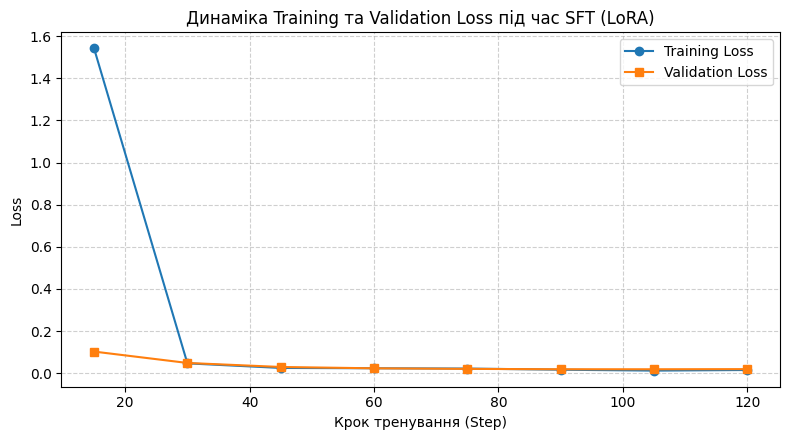

In [4]:
peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    task_type="CAUSAL_LM",
)

sft_config = SFTConfig(
    output_dir="qwen3-0.6b-ade-lora",
    max_length=256,
    per_device_train_batch_size=8,
    gradient_accumulation_steps=2,   # Ефективний батч = 16
    per_device_eval_batch_size=16,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=10,
    max_steps=120,
    eval_strategy="steps",
    eval_steps=15,
    logging_steps=15,
    fp16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    assistant_only_loss=True,
    save_strategy="no",
    report_to="none",
    seed=42,
)

torch.cuda.reset_peak_memory_stats()
trainer = SFTTrainer(
    model=base_model,
    args=sft_config,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    peft_config=peft_config,
)

trainer.model.print_trainable_parameters()
start_time = time.time()
trainer.train()
train_duration_min = (time.time() - start_time) / 60
peak_gpu_gb = torch.cuda.max_memory_allocated() / 1e9

print(f"\nТривалість тренування: {train_duration_min:.2f} хв")
print(f"Пікова памʼять GPU:    {peak_gpu_gb:.2f} GB")

# Збереження адаптера
adapter_dir = "qwen3-0.6b-ade-lora-adapter"
trainer.save_model(adapter_dir)
adapter_size_mb = os.path.getsize(os.path.join(adapter_dir, "adapter_model.safetensors")) / 1e6
print(f"Розмір збереженого адаптера: {adapter_size_mb:.2f} MB")

# Побудова графіка Training та Validation Loss
train_steps = [x["step"] for x in trainer.state.log_history if "loss" in x]
train_losses = [x["loss"] for x in trainer.state.log_history if "loss" in x]
eval_steps = [x["step"] for x in trainer.state.log_history if "eval_loss" in x]
eval_losses = [x["eval_loss"] for x in trainer.state.log_history if "eval_loss" in x]

plt.figure(figsize=(8, 4.5))
plt.plot(train_steps, train_losses, marker="o", label="Training Loss")
plt.plot(eval_steps, eval_losses, marker="s", label="Validation Loss")
plt.title("Динаміка Training та Validation Loss під час SFT (LoRA)")
plt.xlabel("Крок тренування (Step)")
plt.ylabel("Loss")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

## 1.5. Порівняння результатів, аналіз помилок та перевірка на загальних запитах

In [5]:
# Оцінюємо донавчену модель на тому самому тестовому наборі (500 прикладів), але вже з КОРОТКИМ промптом
after_metrics, after_samples = evaluate_model(trainer.model, SHORT_PROMPT)

comparison_df = pd.DataFrame({
    "До донавчання (LONG_PROMPT)": before_metrics,
    "Після SFT LoRA (SHORT_PROMPT)": after_metrics,
})
comparison_df["Приріст (Δ)"] = (
    comparison_df["Після SFT LoRA (SHORT_PROMPT)"] - comparison_df["До донавчання (LONG_PROMPT)"]
).round(2)

print("=== Підсумкова таблиця порівняння на тестовому наборі (500 прикладів) ===")
display(comparison_df)

print("\n=== Порівняння відповідей на тих самих 8 прикладах ДО і ПІСЛЯ донавчання ===")
for idx in range(8):
    txt, gold, pred_before = before_samples[idx]
    _, _, pred_after = after_samples[idx]
    print(f"{idx+1}. Текст:        {txt}")
    print(f"   Еталон:       {gold}")
    print(f"   До SFT:       {pred_before}")
    print(f"   Після SFT:    {pred_after}\n" + "-" * 75)

# Аналіз помилок донавченої моделі
errors = []
for txt, gold_str, pred_str in after_samples:
    gold_obj = json.loads(gold_str)
    _, pred_obj = parse_response(pred_str)
    if pred_obj is None or pred_obj["ade_status"] != gold_obj["ade_status"]:
        err_type = "False Positive (Хибна тривога)" if gold_obj["ade_status"] == "NO_EVENT" else "False Negative (Пропущена реакція)"
        errors.append((err_type, txt, gold_str, pred_str))

print(f"\nУсього помилок класифікації після донавчання: {len(errors)} із {len(after_samples)}")
print("\n=== Приклади помилок донавченої моделі для аналізу ===")
for idx, (err_type, txt, gold_str, pred_str) in enumerate(errors[:5], 1):
    print(f"Помилка {idx} [{err_type}]:")
    print(f"  Текст:     {txt}")
    print(f"  Еталон:    {gold_str}")
    print(f"  Прогноз:   {pred_str}\n")

# Перевірка на загальних запитах поза нашою задачею (чи не деградували загальні здібності моделі)
print("=== Перевірка моделі на загальних запитах поза задачею (Catastrophic Forgetting Check) ===")
general_questions = [
    "What is the capital of Ukraine and what river flows through it?",
    "Explain the difference between a list and a tuple in Python in two sentences.",
    "Write a short 3-line haiku about autumn rain.",
]

for q in general_questions:
    prompt = tokenizer.apply_chat_template(
        [{"role": "system", "content": "You are a helpful assistant."}, {"role": "user", "content": q}],
        tokenize=False, add_generation_prompt=True, enable_thinking=False,
    )
    inputs = tokenizer(prompt, return_tensors="pt").to(trainer.model.device)
    with torch.no_grad():
        out = trainer.model.generate(**inputs, max_new_tokens=80, do_sample=False)
    ans = tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    print(f"❓ Запитання: {q}\n🤖 Відповідь: {ans}\n" + "-" * 75)

=== Підсумкова таблиця порівняння на тестовому наборі (500 прикладів) ===


,До донавчання (LONG_PROMPT),Після SFT LoRA (SHORT_PROMPT),Приріст (Δ)
"Чистий JSON, %",0.00,100.00,100.00
"Валідний JSON, %",100.00,100.00,0.00
"Accuracy ade_status, %",81.40,84.00,2.60
"Accuracy clinical_action, %",81.40,84.00,2.60
"F1 (ADVERSE_EVENT), %",46.86,65.22,18.36



=== Порівняння відповідей на тих самих 8 прикладах ДО і ПІСЛЯ донавчання ===
1. Текст:        Angioimmunoblastic lymphadenopathy with dysproteinemia following doxycycline administration.
   Еталон:       {"ade_status": "ADVERSE_EVENT", "clinical_action": "URGENT_PHARMACOVIGILANCE"}
   До SFT:       ```json
{"ade_status": "ADVERSE_EVENT", "clinical_action": "URGENT_PHARMACOVIGILANCE"}
```
   Після SFT:    {"ade_status": "ADVERSE_EVENT", "clinical_action": "URGENT_PHARMACOVIGILANCE"}
---------------------------------------------------------------------------
2. Текст:        Postoperative imaging did not disclose any intra-orbital abnormalities.
   Еталон:       {"ade_status": "NO_EVENT", "clinical_action": "ROUTINE_LOG"}
   До SFT:       ```json
{"ade_status": "NO_EVENT", "clinical_action": "ROUTINE_LOG"}
```
   Після SFT:    {"ade_status": "NO_EVENT", "clinical_action": "ROUTINE_LOG"}
---------------------------------------------------------------------------
3. Текст:        No patie

## 1.6. Мій звіт

- **Задача і чому потрібне донавчання:**
  Задача полягає в автоматичному фармаконагляді та тріажі клінічних повідомлень (Adverse Drug Events Triage): система отримує на вхід речення з медичної картки чи звіту лікаря і має повернути чистий JSON-об'єкт строго заданої схеми з двома полями — наявністю побічної реакції на препарат (`ade_status`: `"ADVERSE_EVENT"` або `"NO_EVENT"`) та маршрутом клінічної дії (`clinical_action`: `"URGENT_PHARMACOVIGILANCE"` або `"ROUTINE_LOG"`). Користувачами є медичні інформаційні системи (МІС) та відділи фармаконагляду. Звичайного промпту та RAG для цієї задачі недостатньо з трьох причин: по-перше, задача вимагає розрізнення причинно-наслідкових зв'язків у реченні (чи симптом викликаний ліками, чи є причиною їх призначення), а не пошуку в базі знань; по-друге, без донавчання модель `Qwen3-0.6B` у **100% випадків загортає відповідь у Markdown-блок** (````json ... ````), через що частка чистого JSON дорівнює **0.00%**; по-третє, детальний промпт (`LONG_PROMPT`, **197 токенів**) у **13.1 раза довший** за короткий промпт після SFT (`SHORT_PROMPT`, **15 токенів**).

- **Модель і дані:**
  Для вирішення задачі обрано інструктивну модель **`Qwen/Qwen3-0.6B`** (606 млн параметрів), оскільки вона вже навчена працювати з шаблоном діалогу ChatML, займає лише **1.19 GB** відеопам'яті у `fp16` і забезпечує високу швидкість локального (on-premise) інференсу в медичних установах. Використано відкритий біомедичний датасет **`SetFit/ade_corpus_v2_classification`** з Hugging Face Hub (побудований на рецензованих звітах MEDLINE/PubMed, ліцензія MIT). Після текстової дедуплікації (з **17 637** до **15 918** унікальних прикладів) дані перетворено у формат `messages` із вимкненим режимом міркувань (`enable_thinking=False`) і розділено без перетинів на **2400 тренувальних**, **200 валідаційних** та **500 тестових** прикладів.

- **Метрика й результат до донавчання:**
  Оскільки класи в медичному датасеті незбалансовані (близько 70% `NO_EVENT` і 30% `ADVERSE_EVENT`), основною метрикою обрано **`F1-score` за цільовим класом `ADVERSE_EVENT`**, а додатковими — частку чистого JSON (`Чистий JSON, %`), валідного JSON (`Валідний JSON, %`) та точність обох полів (`Accuracy ade_status` і `Accuracy clinical_action`).
  На тестовому наборі з 500 прикладів **до донавчання** (з детальним промптом `LONG_PROMPT` на 197 токенів) отримано такі результати:
  - `Чистий JSON, %`: **0.00%** (усі 500 відповідей містили зайву обгортку ````json ... ````);
  - `Валідний JSON, %` (після примусового зняття обгортки): **100.00%**;
  - `Accuracy ade_status, %` та `Accuracy clinical_action, %`: **81.40%** (достатньо високе значення пояснюється тим, що модель у більшості сумнівних випадків просто обирала мажоритарний клас `NO_EVENT`);
  - `F1 (ADVERSE_EVENT), %`: лише **46.86%** — модель пропустила більшість реальних побічних реакцій на препарати.

- **Метод донавчання й гіперпараметри:**
  Використано метод **SFT із LoRA** (`r=16`, `lora_alpha=32`, `lora_dropout=0.05`, `target_modules="all-linear"`), при якому тренувалося лише **10,092,544 параметрів (1.6650% від усіх 606,142,464 ваг)**. Основні гіперпараметри `SFTConfig`: `learning_rate=2e-4` з косинусним розкладом (`cosine`) та `warmup_steps=10`, ефективний розмір батча **16** (`per_device_train_batch_size=8`, `gradient_accumulation_steps=2`), `max_steps=120`, змішана точність `fp16=True`, `gradient_checkpointing=True` та `assistant_only_loss=True`.
  - **Динаміка Loss:** `Training Loss` знизився з **`1.541437`** (крок 15) до **`0.015000`** (крок 120), а `Validation Loss` плавно впав з **`0.102414`** (крок 15) до мінімуму **`0.018506`** на 105-му кроці та стабілізувався на рівні **`0.019183`** на 120-му кроці (середня точність токенів досягла `99.26%`). Оскільки після 105-го кроку `Validation Loss` вийшов на плато, зупинка на 120 кроках запобігла перенавчанню.
  - **Ресурси:** Тривалість тренування на GPU Tesla T4 склала **3.66 хв**, пікова пам'ять GPU — **1.60 GB**, розмір збереженого адаптера — **40.42 MB**.

- **Результат після донавчання:**
  На тих самих 500 тестових прикладах, але вже з коротким промптом (`SHORT_PROMPT`, **15 токенів**), донавчена модель показала такий результат:
  - `Чистий JSON, %`: зріс з **0.00%** до **100.00%** (**+100.00 в.п.**) — модель повністю перестала додавати Markdown-обгортки;
  - `Валідний JSON, %`: **100.00%**;
  - `Accuracy ade_status, %` та `Accuracy clinical_action, %`: зросли з **81.40%** до **84.00%** (**+2.60 в.п.**);
  - Головна метрика **`F1 (ADVERSE_EVENT), %`**: зросла з **46.86%** до **65.22%** (**+18.36 в.п.**).

- **Аналіз помилок:**
  Після донавчання модель помилилася у **80 із 500** тестових прикладів. Розбір конкретних помилок виявив три типові причини:
  1. **Тяжкий клінічний наслідок основного захворювання на тлі терапії (*False Positive* — Помилка 2):** У реченні *"The patient presented with loss of consciousness and died after 5 days of antifungal therapy with liposomal amphotericin B"* пацієнт помер від основного захворювання попри 5 днів терапії. Донавчена модель зреагувала на конструкцію *"died after ... therapy with [drug]"* і помилково класифікувала це як побічну дію препарату (`ADVERSE_EVENT`).
  2. **Загальні твердження про потенційний ризик замість реального інциденту (*False Positive* — Помилка 3):** У реченні *"Cancer patients who are receiving 5-FU treatment and are DPD deficient can develop severe side effects"* йдеться про теоретичний ризик побічних ефектів у пацієнтів із дефіцитом ферменту DPD. Модель зреагувала на словосполучення *"develop severe side effects"* і видала хибну тривогу.
  3. **Нетипові або відкладені ускладнення зі складною структурою речення (*False Negatives* — Помилки 1, 4, 5):** У прикладах *"Reported are three children who developed progressive paraparesis after intrathecal methotrexate administration followed by complete or partial recovery"* та *"He developed a late secondary infection in some sites treated with imiquimod"* модель пропустила побічну реакцію (`NO_EVENT`), оскільки згадка про повне одужання (*complete recovery*) або вторинну інфекцію змістила фокус уваги малої моделі (0.6B) від токсичності самого препарату.
  - **Перевірка поза задачею (Catastrophic Forgetting Check):** На загальних запитах (столиця і головна річка України — *Kyiv, Dnieper River*; різниця між `list` і `tuple` у Python; написання 3-рядкового хайку про осінній дощ) донавчена модель дала точні й грамотні відповіді, що підтверджує збереження загальних знань завдяки LoRA та `assistant_only_loss=True`.

- **Висновок:**
  Донавчання моделі `Qwen/Qwen3-0.6B` методом SFT + LoRA за **3.66 хв** при піковому використанні **1.60 GB VRAM** дозволило повністю вирішити проблему форматування виходу (частка чистого JSON зросла з **0.00% до 100.00%**), скоротити довжину системного промпту у **13.1 раза** (з 197 до 15 токенів) та підвищити F1-міру виявлення побічних реакцій на ліки з **46.86% до 65.22%** (**+18.36 в.п.**), а загальну точність — з **81.40% до 84.00%** (**+2.60 в.п.**) без втрати загальних мовних здібностей моделі.